# Entregable II — Selección de variables, reducción de dimensión y explicabilidad

Modelos y Simulación de Sistemas II — Universidad de Antioquia — Grupo 14

Este notebook responde tres preguntas sobre el clasificador de riesgo grave de mora:

1. ¿Qué variables tienen más relación con el riesgo, vistas una por una (análisis de
   filtro)?
2. ¿Se puede **simplificar el modelo** (menos variables o menos dimensiones) sin perder
   desempeño? Se comparan selección por información mutua, regresión logística con
   penalización L1 (Lasso), PCA y UMAP.
3. ¿**Qué explica las predicciones**? Coeficientes de la regresión logística, importancia
   por permutación y valores SHAP del Random Forest.

**Mismo protocolo que el notebook 03.** Partición temporal (el 20 % más reciente es la
prueba), validación con pliegues de ventana expansiva, y todo paso que aprende de los datos
(imputación, escalado, selección, PCA) dentro del `Pipeline`, reajustado en cada pliegue.
El análisis individual de la sección 2 usa **solo los episodios de desarrollo**.

**Configuración base.** *K* = 8, *H* = 12, *X* = 14. Según la sección 3 del notebook 03, ni el
perfil de la etapa 1 ni las marcas de gestión mejoran el modelo, así que aquí se trabaja sin
ellos: es el modelo más simple y no depende de decisiones del cobrador.

In [1]:
import functools
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
EN_COLAB = "google.colab" in sys.modules
NOMBRE_CARPETA = "ProyectoModelos2_Colab"


def buscar_carpeta_drive():
    raices = [Path("/content/drive/MyDrive"), *Path("/content/drive").glob(".shortcut-targets-by-id/*")]
    for patron in (NOMBRE_CARPETA, f"*/{NOMBRE_CARPETA}", f"*/*/{NOMBRE_CARPETA}"):
        for raiz in raices:
            for carpeta in raiz.glob(patron):
                if (carpeta / "clasificacion.py").exists():
                    return carpeta
    return None


if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta = buscar_carpeta_drive()
    if carpeta is None:
        raise FileNotFoundError(
            f"No se encontro la carpeta {NOMBRE_CARPETA} en su Drive. Agreguele un acceso directo "
            "en Mi unidad (Compartidos conmigo > clic derecho > Organizar > Agregar acceso directo) "
            "y vuelva a ejecutar todo.")
    os.chdir(carpeta)
    get_ipython().system("pip install -q shap umap-learn")
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DIR_SALIDA = Path("/content/salidas") if EN_COLAB else RAIZ


def ubicar(archivos, carpetas):
    for c in carpetas:
        if all((c / a).exists() for a in archivos):
            return c
    raise FileNotFoundError(f"No se encontraron {archivos} en {[str(c) for c in carpetas]}.")


sys.path.insert(0, str(ubicar(["clasificacion.py", "ciclos.py"], [RAIZ / "src", Path.cwd()])))
DIR_DATOS = ubicar(["abonos.csv.gz", "motos_diario.csv.gz"], [RAIZ / "data" / "anon", Path.cwd()])
DIR_FIG = DIR_SALIDA / "reports" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

import shap
import umap
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel, SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline

from clasificacion import CAT, MARCAS, NUM_BASE, Preprocesador, cargar_base, construir_dataset, evaluar
from particion import corte_por_fraccion, dividir_temporal, pliegues_expansivos

TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#2a9d6f"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
})
CIFRAS = {}
SEMILLA = 0

## 1. Datos y partición

In [2]:
ep, ciclos, pagos, diario, CORTE = cargar_base(DIR_DATOS)
K, H, X = 8, 12, 14
data = construir_dataset(ep, ciclos, pagos, diario, CORTE, pd.Timestamp("2024-03-30"), K, H, X)
COLS = NUM_BASE + CAT                       # sin marcas de gestión
corte = corte_por_fraccion(data.fecha_inicio, 0.2)
i_dev, i_te = dividir_temporal(data.fecha_inicio, K, H, X, corte)
dev, te = data.iloc[i_dev].reset_index(drop=True), data.iloc[i_te].reset_index(drop=True)
print(f"Desarrollo: {len(dev)} episodios ({100 * dev.y.mean():.1f} % positivos) | prueba: {len(te)} ({100 * te.y.mean():.1f} %)")

def base(extra=(), clf=None):
    clf = clf if clf is not None else LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced")
    return Pipeline([("pre", Preprocesador(con_perfil=False, con_marcas=False, seed=SEMILLA)), *extra, ("clf", clf)])

Desarrollo: 1735 episodios (32.0 % positivos) | prueba: 582 (38.7 %)


## 2. Análisis individual de las variables (filtro)

Con los episodios de **desarrollo** se mide, para cada variable ya imputada y estandarizada,
tres señales de su relación con el riesgo grave: el **AUC univariado** (qué tan bien ordena
los episodios por sí sola; se reporta el valor mayor entre AUC y 1 − AUC para ignorar el
signo), la **información mutua** con la etiqueta y la **correlación de Spearman**. Los
indicadores `missingindicator_*` marcan si el valor original faltaba (por ejemplo, un
episodio sin pagos en la ventana).

,AUC univariado,signo,información mutua,Spearman
variable,,,,
atraso_promedio,0.759,+,0.106,0.426
deficit_relativo,0.749,+,0.118,0.403
prop_ciclos_atrasados,0.731,+,0.087,0.381
pago_canon_total,0.727,−,0.091,-0.367
prop_ciclos_atraso_3mas,0.721,+,0.081,0.428
ciclos_sin_pagar_k,0.717,+,0.096,0.440
pagos_por_ciclo,0.713,−,0.081,-0.409
empresa_RENTAYA,0.646,+,0.042,0.297
empresa_MOTOHOY,0.646,−,0.025,-0.297


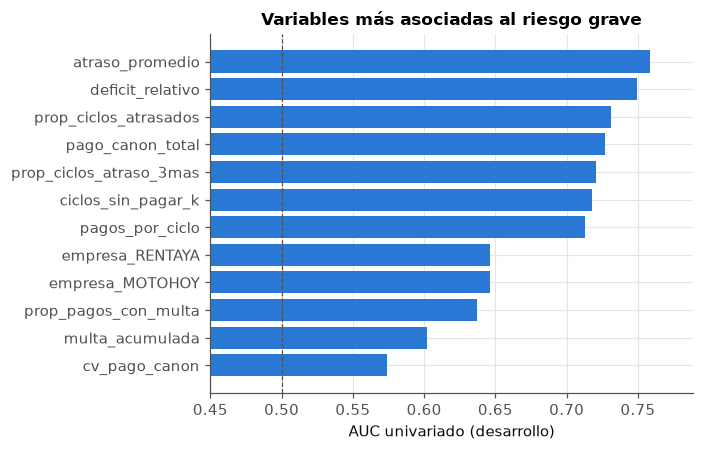

Pares de variables con |Spearman| > 0,8 (redundantes):


,,|ρ|
prop_ciclos_atrasados,atraso_promedio,0.97
multa_acumulada,prop_pagos_con_multa,0.96
ciclos_sin_pagar_k,pagos_por_ciclo,0.91
prop_ciclos_atraso_3mas,atraso_promedio,0.82


In [3]:
pre = Preprocesador(con_perfil=False, con_marcas=False, seed=SEMILLA).fit(dev[COLS])
Z = pre.transform(dev[COLS])
nombres = pre.get_feature_names_out()
y_dev = dev.y.to_numpy()
mi = mutual_info_classif(Z, y_dev, random_state=SEMILLA)
filas = []
for j, n in enumerate(nombres):
    if Z[:, j].std() == 0:
        continue
    auc = roc_auc_score(y_dev, Z[:, j])
    filas.append({"variable": n, "AUC univariado": max(auc, 1 - auc), "signo": "+" if auc >= 0.5 else "−",
                  "información mutua": mi[j], "Spearman": spearmanr(Z[:, j], y_dev)[0]})
indiv = pd.DataFrame(filas).set_index("variable").sort_values("AUC univariado", ascending=False)
display(indiv.head(15).round(3))
CIFRAS["individual_top15"] = indiv.head(15).round(4).to_dict(orient="index")

top = indiv.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(top.index, top["AUC univariado"], color=AZUL)
ax.axvline(0.5, color=TINTA_2, lw=0.8, ls="--")
ax.set_xlim(0.45, top["AUC univariado"].max() + 0.03)
ax.set_xlabel("AUC univariado (desarrollo)"); ax.set_title("Variables más asociadas al riesgo grave")
fig.tight_layout(); fig.savefig(DIR_FIG / "auc_univariado.png"); plt.show()

num_dev = pd.DataFrame(Z, columns=nombres)[[n for n in nombres if n in NUM_BASE]]
corr = num_dev.corr(method="spearman").abs()
pares = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False))
pares = pares[pares > 0.8]
print("Pares de variables con |Spearman| > 0,8 (redundantes):")
display(pares.round(2).to_frame("|ρ|"))
CIFRAS["pares_redundantes"] = {f"{a} ~ {b}": round(float(v), 3) for (a, b), v in pares.items()}

**Lectura.** Las variables más asociadas al riesgo son las de atraso: el atraso promedio
(AUC univariado 0,759), el déficit relativo de pago (0,749), la proporción de ciclos con atraso
(0,731) y, en sentido contrario, el pago total al canon (0,727: pagar más protege). Ninguna
supera por sí sola 0,76, así que el modelo se apoya en varias variables a la vez. La empresa
también se asocia (RENTAYA, 0,646). Hay cuatro pares de variables casi duplicadas (|ρ| > 0,8),
lo que confirma las redundancias que ya se habían visto en el EDA; por ejemplo, el atraso
promedio y la proporción de ciclos atrasados (0,97).

## 3. Selección y reducción de variables dentro de la validación

Se comparan, con la misma validación temporal, la regresión logística y el Random Forest
usando: todas las variables; las *k* mejores por información mutua (*k* = 5, 8, 12);
la selección por **Lasso** (regresión logística con penalización L1, que lleva a cero los
coeficientes poco útiles); **PCA** con 5, 8 y 12 componentes; y **UMAP** de 5 dimensiones.
La selección y la proyección se **reajustan en cada pliegue** con sus datos de
entrenamiento. UMAP no usa la etiqueta, así que aquí sirve de prueba de qué tanto sirve una
reducción no supervisada de la estructura local como entrada de un clasificador.

In [4]:
mi_fn = functools.partial(mutual_info_classif, random_state=SEMILLA)
lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, class_weight="balanced")
RF = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=SEMILLA)
variantes = {
    "todas las variables": [],
    "información mutua, k = 5": [("sel", SelectKBest(mi_fn, k=5))],
    "información mutua, k = 8": [("sel", SelectKBest(mi_fn, k=8))],
    "información mutua, k = 12": [("sel", SelectKBest(mi_fn, k=12))],
    "Lasso (L1)": [("sel", SelectFromModel(lasso))],
    "PCA, 5 componentes": [("pca", PCA(5, random_state=SEMILLA))],
    "PCA, 8 componentes": [("pca", PCA(8, random_state=SEMILLA))],
    "PCA, 12 componentes": [("pca", PCA(12, random_state=SEMILLA))],
    "UMAP, 5 dimensiones": [("umap", umap.UMAP(n_components=5, random_state=SEMILLA))],
}
filas = []
for nombre, extra in variantes.items():
    for modelo, mk in (("Regresión logística", None), ("Random Forest", RF)):
        if nombre.startswith("UMAP") and modelo == "Random Forest":
            continue
        r = evaluar(base(extra, mk() if mk else None), data, COLS, K, H, X)
        filas.append({"reducción": nombre, "modelo": modelo,
                      "AUC validación": f"{r['auc_validacion']:.3f} ± {r['auc_validacion_sd']:.3f}",
                      "AUC prueba": round(r["prueba"]["AUC"], 3), "BACC prueba": round(r["prueba"]["BACC"], 3),
                      "MCC prueba": round(r["prueba"]["MCC"], 3)})
reduccion = pd.DataFrame(filas)
display(reduccion)
CIFRAS["reduccion"] = reduccion.to_dict(orient="records")

,reducción,modelo,AUC validación,AUC prueba,BACC prueba,MCC prueba
0,todas las variables,Regresión logística,0.809 ± 0.021,0.757,0.690,0.373
1,todas las variables,Random Forest,0.799 ± 0.021,0.783,0.698,0.413
2,"información mutua, k = 5",Regresión logística,0.788 ± 0.030,0.773,0.722,0.435
3,"información mutua, k = 5",Random Forest,0.780 ± 0.035,0.769,0.717,0.424
4,"información mutua, k = 8",Regresión logística,0.789 ± 0.029,0.775,0.711,0.435
5,"información mutua, k = 8",Random Forest,0.780 ± 0.029,0.783,0.720,0.430
6,"información mutua, k = 12",Regresión logística,0.786 ± 0.026,0.778,0.704,0.430
7,"información mutua, k = 12",Random Forest,0.779 ± 0.027,0.792,0.720,0.440
8,Lasso (L1),Regresión logística,0.800 ± 0.020,0.762,0.696,0.418
9,Lasso (L1),Random Forest,0.803 ± 0.020,0.781,0.689,0.394


**Lectura.** Simplificar el modelo no hace perder desempeño de forma clara. Con solo 5
variables elegidas por información mutua, la regresión logística tiene un AUC de validación de
0,788 frente a 0,809 con todas (una diferencia menor que la variabilidad entre pliegues, ≈ 0,03)
y en prueba 0,773 frente a 0,757; el Lasso conserva 0,800 y el Random Forest 0,802. PCA no
aporta ventaja (0,77 a 0,80 según el modelo y el número de componentes) y UMAP como entrada del
clasificador rinde mucho peor (0,665), lo esperable de una proyección que no usa la etiqueta.
Las diferencias entre validación y prueba van en sentidos opuestos, así que no son
concluyentes. Lo útil es que un modelo de 5 a 8 variables rinde de forma equivalente a uno con
todas y es más fácil de explicar y de calcular en la empresa.

### 3.1 ¿Qué variables eligen los métodos y qué tan estable es la elección?

Se cuenta en cuántos de los pliegues de validación cada variable es elegida por la
información mutua (*k* = 8) y por el Lasso. Una variable elegida en todos los pliegues es una
señal estable; una elegida en uno solo depende del periodo.

In [5]:
pliegues = [(tr, va) for tr, va in pliegues_expansivos(data.fecha_inicio, K, H, X, 4, fecha_max=corte) if len(tr) >= 100]
conteo = {"información mutua (k = 8)": {}, "Lasso": {}}
for tr, _ in pliegues:
    d = data.iloc[tr]
    for etiqueta_met, sel in (("información mutua (k = 8)", SelectKBest(mi_fn, k=8)), ("Lasso", SelectFromModel(lasso))):
        p = Pipeline([("pre", Preprocesador(False, False, seed=SEMILLA)), ("sel", sel)]).fit(d[COLS], d.y)
        elegidas = p.named_steps["pre"].get_feature_names_out()[p.named_steps["sel"].get_support()]
        for n in elegidas:
            conteo[etiqueta_met][n] = conteo[etiqueta_met].get(n, 0) + 1
est = pd.DataFrame(conteo).fillna(0).astype(int)
est = est.assign(total=est.sum(axis=1)).sort_values("total", ascending=False).drop(columns="total")
est.index.name = f"variable (de {len(pliegues)} pliegues)"
display(est.head(15))
CIFRAS["estabilidad_seleccion"] = est.head(15).to_dict(orient="index")

,información mutua (k = 8),Lasso
variable (de 3 pliegues),,
prop_ciclos_atraso_3mas,3,3
ciclos_sin_pagar_k,3,3
cv_pago_canon,3,3
deficit_relativo,3,3
prop_ciclos_atrasados,3,2
atraso_promedio,3,2
pago_canon_total,3,0
pagos_por_ciclo,3,0
multa_acumulada,0,3


**Lectura.** Tanto la información mutua como el Lasso eligen en todos los pliegues la
proporción de ciclos con 3 o más días de atraso, los ciclos sin pagar, la variabilidad del pago
(`cv_pago_canon`) y el déficit relativo. La información mutua además conserva las variables de
atraso y pago redundantes entre sí; el Lasso las descarta y se queda con la multa acumulada, las
justificaciones por inmovilización y la empresa. Es una señal estable: el núcleo de variables
relevantes no depende del periodo usado para elegirlas.

## 4. PCA: cuánta información comprimen las componentes

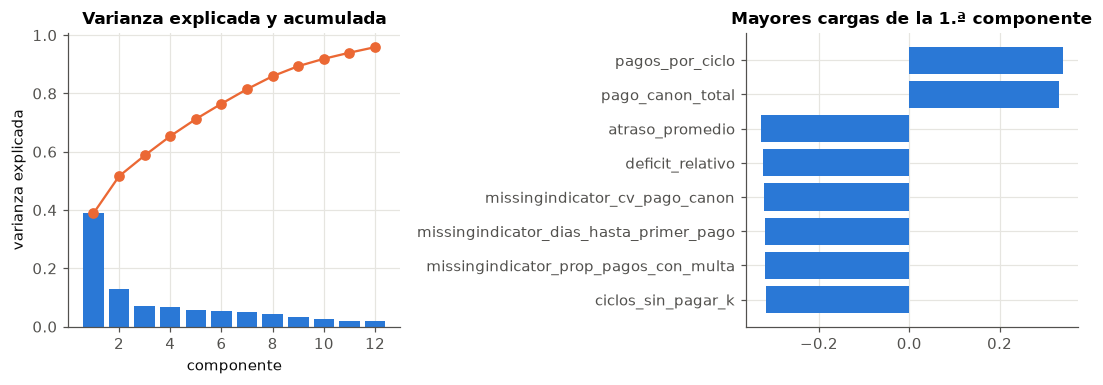

Se necesitan 10 componentes para explicar el 90 % de la varianza (28 variables).


In [6]:
pca = PCA(random_state=SEMILLA).fit(Z)
acum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(range(1, 13), pca.explained_variance_ratio_[:12], color=AZUL)
ax[0].plot(range(1, 13), acum[:12], color=NARANJA, marker="o")
ax[0].set_xlabel("componente"); ax[0].set_ylabel("varianza explicada"); ax[0].set_title("Varianza explicada y acumulada")
cargas = pd.DataFrame(pca.components_[:2].T, index=nombres, columns=["PC1", "PC2"])
c1 = cargas.reindex(cargas.PC1.abs().sort_values(ascending=False).index).head(8).iloc[::-1]
ax[1].barh(c1.index, c1.PC1, color=AZUL); ax[1].set_title("Mayores cargas de la 1.ª componente")
fig.tight_layout(); fig.savefig(DIR_FIG / "pca_varianza.png"); plt.show()
n90 = int(np.searchsorted(acum, 0.9) + 1)
print(f"Se necesitan {n90} componentes para explicar el 90 % de la varianza ({len(nombres)} variables).")
CIFRAS["pca"] = {"n_variables": len(nombres), "componentes_90": n90, "varianza_pc1_pc2": pca.explained_variance_ratio_[:2].round(4).tolist()}

**Lectura.** La información está repartida: la primera componente explica solo el 39 % de la
varianza, las dos primeras el 52 %, y se necesitan 10 componentes de 28 variables para llegar al
90 %. No hay una dimensión dominante, lo que explica que PCA no mejore la clasificación.

## 5. Explicabilidad

Se ajusta cada modelo con todo el desarrollo y se explica su comportamiento. Los resultados
describen **qué usa el modelo**, no causas: que una variable se asocie con el riesgo no
significa que provocarlo.

### 5.1 Regresión logística: coeficientes

Con variables estandarizadas, el coeficiente indica cuánto cambia el logaritmo de las
probabilidades de riesgo grave por cada desviación estándar de la variable.

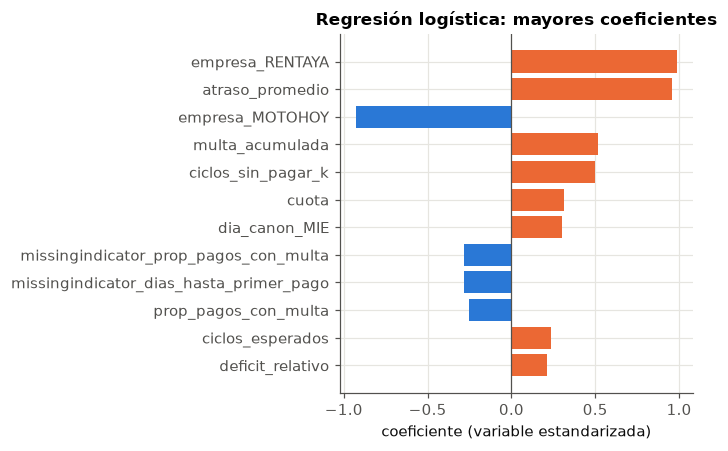

In [7]:
logit = LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced").fit(Z, y_dev)
coef = pd.Series(logit.coef_[0], index=nombres)
coef = coef[coef.abs().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
c = coef.head(12).iloc[::-1]
ax.barh(c.index, c.values, color=[NARANJA if v > 0 else AZUL for v in c.values])
ax.axvline(0, color=TINTA_2, lw=0.8)
ax.set_xlabel("coeficiente (variable estandarizada)"); ax.set_title("Regresión logística: mayores coeficientes")
fig.tight_layout(); fig.savefig(DIR_FIG / "coeficientes_logistica.png"); plt.show()
CIFRAS["coeficientes_top12"] = coef.head(12).round(4).to_dict()

**Lectura.** Los mayores coeficientes son el atraso promedio (+0,96), la multa acumulada
(+0,52) y los ciclos sin pagar (+0,50): más atraso, más multas y más cuotas sin pagar
aumentan el riesgo. La empresa aparece con coeficientes grandes y opuestos
(RENTAYA +0,99, MOTOHOY −0,93); son dos columnas complementarias de una misma variable, así
que lo que importa es su diferencia, no cada valor por separado.

### 5.2 Random Forest: importancia por permutación y valores SHAP

La **importancia por permutación** mide cuánto cae el AUC cuando se baraja una variable
(se calcula sobre la prueba, solo para describir el modelo final). Los **valores SHAP**
reparten la predicción de cada episodio entre las variables; el gráfico muestra, para cada
variable, cómo se reparte su efecto según sea alto o bajo su valor.

,caída del AUC al barajar
deficit_relativo,0.0263
atraso_promedio,0.0206
prop_ciclos_atraso_3mas,0.0098
ciclos_sin_pagar_k,0.0081
multa_acumulada,0.0071
empresa_RENTAYA,0.0065
empresa_MOTOHOY,0.0052
cv_pago_canon,0.0051
pagos_por_ciclo,0.0034
prop_ciclos_atrasados,0.0033


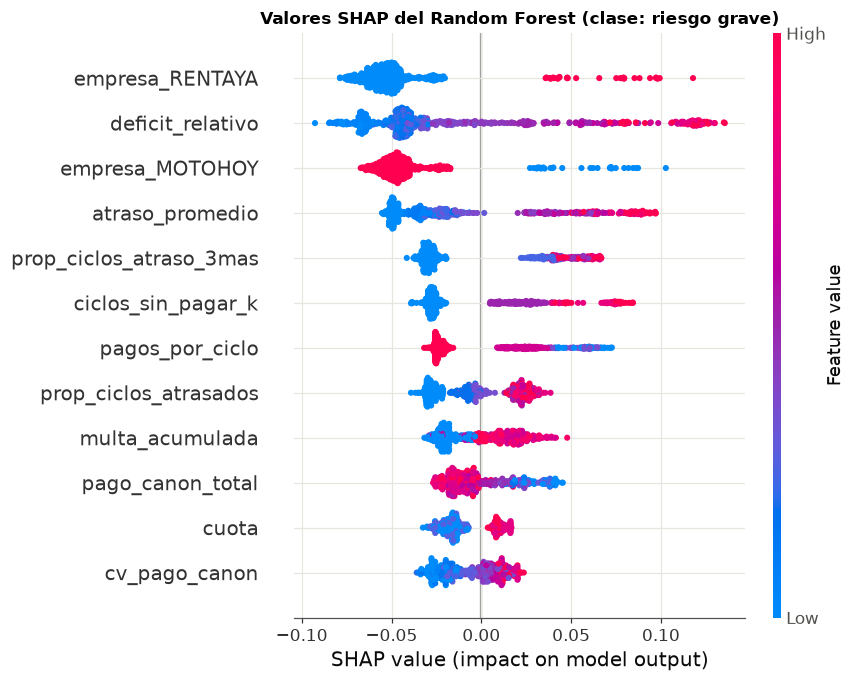

In [8]:
rf = RF().fit(Z, y_dev)
Z_te = pre.transform(te[COLS])
perm = permutation_importance(rf, Z_te, te.y, scoring="roc_auc", n_repeats=20, random_state=SEMILLA)
imp = pd.Series(perm.importances_mean, index=nombres).sort_values(ascending=False)
display(imp.head(10).round(4).to_frame("caída del AUC al barajar"))
CIFRAS["permutacion_top10"] = imp.head(10).round(4).to_dict()

expl = shap.TreeExplainer(rf)
sv = expl(Z_te)
valores = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values
shap.summary_plot(valores, Z_te, feature_names=nombres, max_display=12, show=False)
plt.title("Valores SHAP del Random Forest (clase: riesgo grave)")
plt.tight_layout(); plt.savefig(DIR_FIG / "shap_resumen.png"); plt.show()
shap_medio = pd.Series(np.abs(valores).mean(axis=0), index=nombres).sort_values(ascending=False)
CIFRAS["shap_top10"] = shap_medio.head(10).round(4).to_dict()

**Lectura.** Según la permutación, las variables que más pesan son el déficit relativo (el
AUC cae 0,026 al barajarla) y el atraso promedio (0,021). Según SHAP, las que más contribuyen
son la empresa (RENTAYA), el déficit relativo y el atraso promedio. En el gráfico SHAP los
valores altos de atraso y de déficit empujan la predicción hacia riesgo grave, y los valores altos de pago
total la empujan hacia lo contrario.

### 5.3 ¿Coinciden los métodos?

Si métodos muy distintos (un modelo lineal, un bosque y un filtro) señalan las mismas
variables, la conclusión es más confiable.

In [9]:
rankings = pd.DataFrame({
    "AUC univariado": indiv["AUC univariado"],
    "|coef.| logística": coef.abs(),
    "permutación RF": imp,
    "|SHAP| RF": shap_medio,
}).dropna()
rho = rankings.rank().corr(method="spearman").round(2)
display(rho)
top5 = {c: list(rankings[c].sort_values(ascending=False).head(5).index) for c in rankings.columns}
for c, v in top5.items():
    print(f"{c}: {', '.join(v)}")
CIFRAS["acuerdo_rankings"] = rho.to_dict()
CIFRAS["top5_por_metodo"] = top5

,AUC univariado,|coef.| logística,permutación RF,|SHAP| RF
AUC univariado,1.00,0.46,0.60,0.87
|coef.| logística,0.46,1.00,0.34,0.54
permutación RF,0.60,0.34,1.00,0.61
|SHAP| RF,0.87,0.54,0.61,1.00


AUC univariado: atraso_promedio, deficit_relativo, prop_ciclos_atrasados, pago_canon_total, prop_ciclos_atraso_3mas
|coef.| logística: empresa_RENTAYA, atraso_promedio, empresa_MOTOHOY, multa_acumulada, ciclos_sin_pagar_k
permutación RF: deficit_relativo, atraso_promedio, prop_ciclos_atraso_3mas, ciclos_sin_pagar_k, multa_acumulada
|SHAP| RF: empresa_RENTAYA, deficit_relativo, empresa_MOTOHOY, atraso_promedio, prop_ciclos_atraso_3mas


**Lectura.** Los métodos coinciden en lo esencial: el atraso promedio, el déficit relativo,
la proporción de ciclos con 3 o más días de atraso y los ciclos sin pagar aparecen entre las
cinco variables principales en varios de ellos. El AUC univariado y SHAP concuerdan bastante
(ρ = 0,87); la regresión logística y la permutación concuerdan menos (0,34), porque entre
variables casi duplicadas los modelos reparten la importancia de forma distinta.

**Dos cautelas.** (1) Estas importancias describen qué usa el modelo, no causas. (2) La
**empresa** tiene un peso grande en la regresión logística y en SHAP. Es una característica
del contrato conocida desde el inicio, pero conviene confirmar con la empresa que el campo es
confiable y qué diferencia a RENTAYA de MOTOHOY (por ejemplo, el tipo de cliente o de moto),
porque un efecto tan grande puede reflejar una diferencia de operación y no de comportamiento.

In [10]:
(DIR_SALIDA / "reports" / "cifras_seleccion.json").write_text(
    json.dumps(CIFRAS, indent=2, ensure_ascii=False, default=lambda o: float(o) if hasattr(o, "item") else str(o)),
    encoding="utf-8")
print("Resultados guardados en", DIR_SALIDA / "reports")

Resultados guardados en C:\Users\LeNoVo\Documents\proyecto_modelos_2\reports
